# Importing the dependencies 

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

### creating a sample customer dataset 


In [23]:
data = {
    "Annual_Income": [
        15, 18, 20, 22, 25,
        45, 48, 50, 52, 55,
        75, 80, 85, 90, 95
    ],
    "Spending_Score": [
        20, 25, 18, 30, 22,
        45, 50, 48, 55, 52,
        75, 80, 78, 85, 90
    ]
}

df = pd.DataFrame(data)


# This is a mini dataset of 15 customers showing their annual income and their spending score

In [24]:
# Select the features

X = df[["Annual_Income", "Spending_Score"]]


In [25]:
# Scaling the features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [26]:
# Training the KMeans model

# Initializing the Kmeans model
model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)


# n_clusters=3: Tells the model to group the data into 3 clusters.
# random_state=42: Ensures you get consistent results each time you run the code.
# n_init=10: Runs K-Means with 10 different initial centroid selections and keeps the best result.



# Model training
df["Cluster"] = model.fit_predict(X_scaled)



model.fit_predict(X_scaled) does two things:
- fit: Trains the K-Means model on the scaled data.
- predict: Assigns each data point to a cluster.


df["Cluster"] = creates a new column in the DataFrame to store each customer's cluster number (e.g., 0, 1, or 2).

In [27]:
# Displaying the dataframe


print(df)

    Annual_Income  Spending_Score  Cluster
0              15              20        2
1              18              25        2
2              20              18        2
3              22              30        2
4              25              22        2
5              45              45        0
6              48              50        0
7              50              48        0
8              52              55        0
9              55              52        0
10             75              75        1
11             80              80        1
12             85              78        1
13             90              85        1
14             95              90        1


### Visualize the clusters

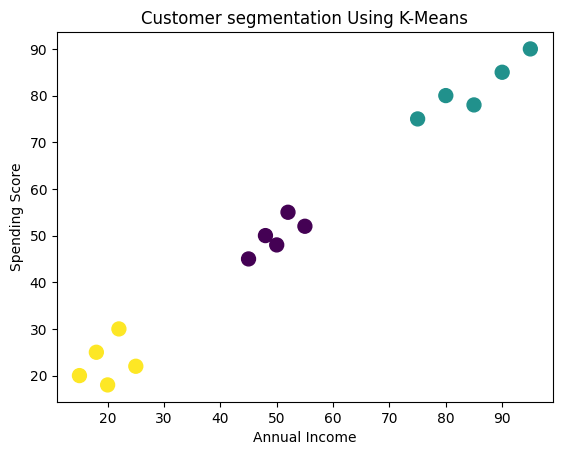

In [28]:
plt.scatter(
    df["Annual_Income"],
    df["Spending_Score"],
    c=df["Cluster"],
    cmap='viridis',
    s=100
)



plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer segmentation Using K-Means")
plt.show()